In [3]:
import pandas as pd
from sklearn.utils import resample
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
chai_df = pd.read_excel('tea_preference.xlsx')
chai_df

,Person,Milk_water_ratio
0,1,1.0
1,2,1.0
2,3,2.0
3,4,1.0
4,5,2.0
5,6,1.0
6,7,1.0
7,8,1.0
8,9,1.0
9,10,2.0


In [5]:
chai_df.describe()

,Person,Milk_water_ratio
count,60.000000,60.000000
mean,30.500000,1.383333
std,17.464249,0.570212
min,1.000000,1.000000
25%,15.750000,1.000000
50%,30.500000,1.000000
75%,45.250000,2.000000
max,60.000000,3.000000


In [6]:
bootstrap_means = []
confidence_interval = 0.95

for _ in range(1000):
    resample_df = resample(chai_df, replace=True, n_samples=len(chai_df))
    bs_mean = resample_df['Milk_water_ratio'].mean()
    bootstrap_means.append(bs_mean)


bootstrap_means = pd.Series(bootstrap_means)
lower_lim = bootstrap_means.quantile(0.025)
upper_lim = bootstrap_means.quantile(0.975)

print(f'Lower limit of Confidence Interval is: {lower_lim}')
print(f'Upper limit of Confidence Interval is: {upper_lim}')
print(f'We are 95% confident (in the sense of the method) that the average milk-to-water ratio lies between {lower_lim} and {upper_lim}')


Lower limit of Confidence Interval is: 1.2333333333333334
Upper limit of Confidence Interval is: 1.525
We are 95% confident (in the sense of the method) that the average milk-to-water ratio lies between 1.2333333333333334 and 1.525


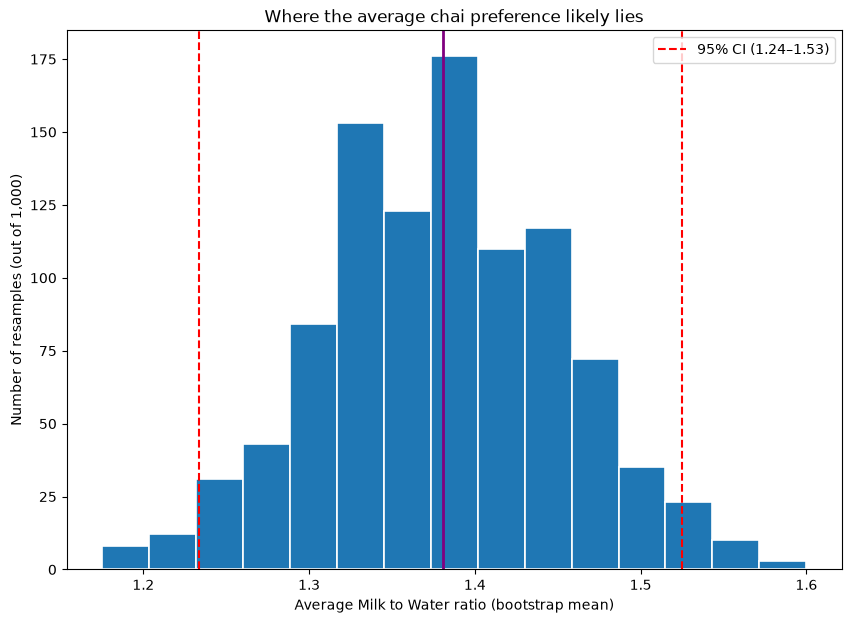

In [7]:
plt.figure(figsize=(10,7))
plt.hist(bootstrap_means, bins=15, edgecolor='white', linewidth=1.2)
plt.axvline(lower_lim, color='red', linestyle = '--',label='95% CI (1.24–1.53)')
plt.axvline(upper_lim, color='red', linestyle = '--')
plt.axvline(bootstrap_means.mean(), color='purple', linewidth=2)
plt.xlabel('Average Milk to Water ratio (bootstrap mean)')
plt.ylabel('Number of resamples (out of 1,000)')
plt.title('Where the average chai preference likely lies')
plt.legend()
plt.show()